Quality control for HVS detection. In particular for Rey who has the most HVS but whose detection seems to be super low.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
import platform
from pathlib import Path
from os import environ
if platform.system() == "Darwin": # Nat laptop
    sys.path.extend(['/Users/nkinsky/Documents/UM/GitHub/NeuroPy'])
    sys.path.extend(['/Users/nkinsky/Documents/UM/GitHub/Projects_sandbox'])
elif (platform.system() == "Windows") and (environ["COMPUTERNAME"] == "WSAN0704"):
    sys.path.extend([r"C:\Users\nkinsky\Documents\Github\NeuroPy"])
    sys.path.extend([r"D:\data\Nat\Github\Project_sandbox\Projects_sandbox"])
else:
    if ("HOSTNAME" in environ.keys()) and (environ["HOSTNAME"] == "lnx00004"): # Nat Linux computer
        sys.path.extend(['/data/GitHub/NeuroPy'])
        sys.path.extend(['/data/GitHub/Projects_sandbox'])
    
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
import scipy.signal as sg
import scipy.io as sio
import matplotlib.pyplot as plt
from neuropy.utils.mathutil import min_max_scaler
from scipy.ndimage import gaussian_filter1d, gaussian_filter
from copy import deepcopy
from tqdm import tqdm

from neuropy import plotting
from neuropy.analyses.placefields import Pf1D, Pf1Dsplit
from neuropy.analyses.oscillations import detect_theta_epochs
from neuropy.core.position import Position
from neuropy.core.epoch import Epoch
from neuropy.core.session import ProcessData
from neuropy.plotting.ratemaps import plot_ratemap
from neuropy.plotting.figure import Fig
from neuropy.utils.misc import flatten
from neuropy.io import BinarysignalIO, NeuroscopeIO
from neuropy.io.miniscopeio import MiniscopeIO
from neuropy.io.sleepscoremasterio import SleepScoreIO
from neuropy.io.dlcio import DLC
from neuropy.utils.mathutil import min_max_scaler, min_max_external_scaler, quantile_scaler

from Psilocybin.subjects import get_psi_dir
from Psilocybin.sleepscoring.HVS_Detection import detect_hvs_epochs, chan_dict, get_good_times

# These are crucial parameters - otherwise all text gets output with each letter in a word or heading as a separate unit
# instead of a text box
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# Specify Arial as font type - also crucial
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'


C:\ProgramData\miniforge3\envs\NeuroPy\Lib\site-packages\xarray\__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Error importing CuPy. Install CuPy to speed up correlogram calculations.
subjects.py Path module=pathlib and pathlib.__file__ = C:\ProgramData\miniforge3\envs\NeuroPy\Lib\pathlib.py
HVS_Detection.py Path module=pathlib and pathlib.__file__ = C:\ProgramData\miniforge3\envs\NeuroPy\Lib\pathlib.py


## Load in animal data

Running Saline1 session
Starting HVS detection
Signal sampling rate: 1250, channels: 21
Selected channel for HVS: 21
187 epochs remaining with durations within (0.2,20)
64 epochs remaining with durations within (0.2,20)
Detected 187 high-band spindles, 64 low-band events, 84 HVS epochs after intersection.


mean=6.284580605286243 std=842.3792086623693

Running Psilocybin session
Starting HVS detection
Signal sampling rate: 1250, channels: 21
Selected channel for HVS: 21
1052 epochs remaining with durations within (0.2,20)
25 epochs remaining with durations within (0.2,20)
Detected 1052 high-band spindles, 25 low-band events, 34 HVS epochs after intersection.


mean=-4.1323540525486395 std=953.9059983072827

Running Saline2 session
Starting HVS detection
Signal sampling rate: 1250, channels: 21
Selected channel for HVS: 21
488 epochs remaining with durations within (0.2,20)
76 epochs remaining with durations within (0.2,20)
Detected 488 high-band spindles, 76 low-band events, 94 HVS epo

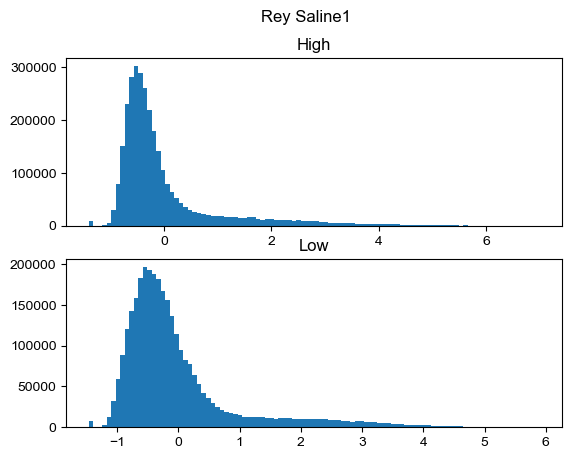

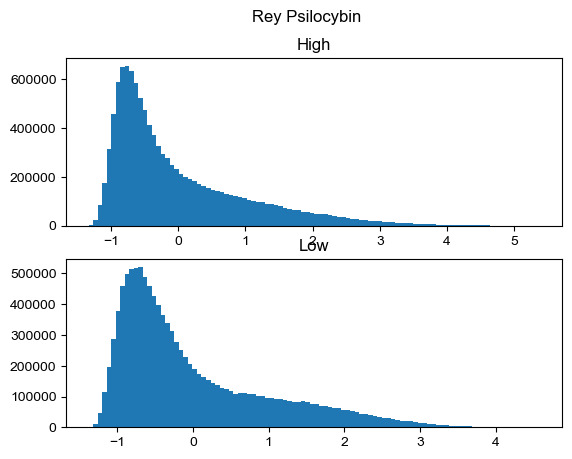

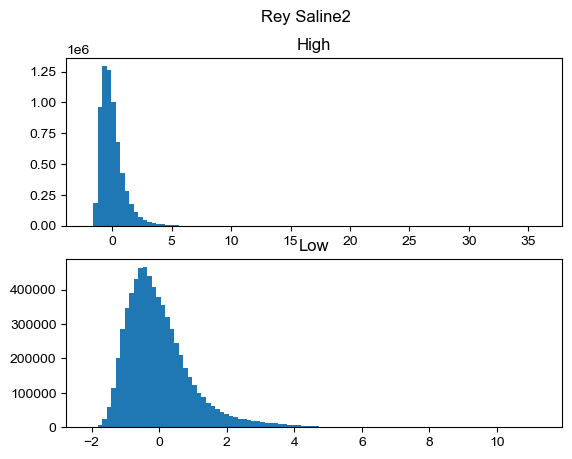

In [2]:
animal = "Rey"

thresh2 = (4, None)

for session in ["Saline1", "Psilocybin", "Saline2"]:
    print(f"Running {session} session")
    # Load in session
    sess = ProcessData(get_psi_dir(animal, session))
    pyr_channel = chan_dict[animal]["Psilocybin"]
    # pyr_channel = 2
    sess.recinfo = NeuroscopeIO(sorted(sess.basepath.glob("*.xml"))[0])
    signal = BinarysignalIO(sess.filePrefix.with_suffix(".eeg"), 
                            n_channels=sess.recinfo.n_channels,
                            sampling_rate=sess.recinfo.eeg_sampling_rate).get_signal(channel_indx=pyr_channel)
    
    # Load in artifact.npy file for each session as "art_epochs"
    try:
        art_epochs = Epoch(epochs=None, 
                           file=sorted(sess.basepath.glob("*.artifact.npy"))[0])
    except ModuleNotFoundError:
        files = sorted(sess.basepath.glob("*.art_epochs.mat"))

        assert len(files) == 1, f"1 state file expected, f{len(files)} files found"
        file = files[0]
        
        art_epochs_mat = sio.loadmat(file, simplify_cells=True)
        art_epochs = Epoch(pd.DataFrame({"start": art_epochs_mat['starts'], "stop": art_epochs_mat['stops'], "label": "artifact"}))
        
        
    # Run HVS detection
    hvs_epochs, power_high, power_low = detect_hvs_epochs(signal, 
                                                          ignore_epochs=art_epochs, 
                                                          thresh2=thresh2,
                                                          return_power=True)
    
    fig, ax = plt.subplots(2, 1)
    ax[0].hist(power_high, 100)
    ax[0].set_title("High")
    ax[1].hist(power_low, 100)
    ax[1].set_title("Low")
    fig.suptitle(f"{animal} {session}")
    print("\n")
    _, art_bool = art_epochs.to_point_process(signal.t_start, signal.t_stop, 1/ signal.sampling_rate)
    print(f"mean={signal.traces[:, ~art_bool[:-1]].mean()} std={signal.traces[:, ~art_bool[:-1]].std()}\n")

In [ ]:
from neuropy.utils import signal_process
lf = 6
hf = 12
fs = signal.sampling_rate
signal_bp = signal_process.filter_sig.bandpass(signal, lf=lf, hf=hf, fs=fs)

In [ ]:
# HVS were identified if the filtered LFP trace exceeded a trough threshold set as 6 SD below the baseline trace with at least 4 troughs below this threshold 
# and with a maximum inter-trough interval of 250 ms. The start and end time was assigned at the point when the signal first and last exceeded a threshold of 2.5 SD.
_, art_bool = art_epochs.to_point_process(signal.t_start, signal.t_stop, 1 / signal.sampling_rate)
signal_bp.traces[:, ~art_bool[:-1]].mean()
bp_mean, bp_std = signal_bp.traces[:, ~art_bool[:-1]].mean(), signal_bp.traces[:, ~art_bool[:-1]].std()
signal_bp.traces[0].min()

In [ ]:
session

In [ ]:
_, ax = plt.subplots()
ax.plot(signal_bp.time[0:20000], signal_bp.traces[0, 0:20000])

In [ ]:
good_bool

In [ ]:
ttrough_mean

In [ ]:
event_ind

In [ ]:
start_end_inds = contiguous_regions(start_end_bool)
(37.4 > signal_bp.time[start_end_inds][:, 0]) & (37.4 < signal_bp.time[start_end_inds][:, 1])

In [ ]:
start

In [ ]:
len(start_stop_use)

In [ ]:
start_end_times[680:690, :]

In [ ]:
(start > signal_bp.time[start_end_inds][:, 0])

In [ ]:
start_end_times[start > signal_bp.time[start_end_inds][:, 0]][-1, 0]

In [ ]:
event_inds[good_bool, :]

In [ ]:
signal_bp.time[contiguous_regions(cand_bool)]

In [ ]:
event_inds[good_bool, 0]

In [ ]:
cand_event_starts = signal_bp.time[contiguous_regions(cand_bool)][event_inds[good_bool, 0], 0]
cand_event_stops = signal_bp.time[contiguous_regions(cand_bool)][event_inds[good_bool, 0], 1]

In [ ]:
signal_bp.time[contiguous_regions(cand_bool)][event_inds[good_bool, 0], 0]

In [ ]:
signal_bp.time[contiguous_regions(cand_bool)][event_inds[good_bool, 1], 1]

## Test code to detect HVS in line with Haggerty ... & Ji / Domenico ... & Ji papers

"HVS were identified if the filtered LFP trace exceeded a trough threshold set as 6 SD below the baseline trace with at least 4 troughs below this threshold and with a maximum inter-trough interval of 250 ms. The start and end time was assigned at the point when the signal first and last exceeded a threshold of 2.5 SD."

I need to adjust thresholds because our deflections do not reach the 6 std criteria that they use.

In [11]:
inj_time = Epoch(epochs=None, file=sorted(sess.basepath.glob("*.injection.npy"))[0])["POST"].starts[0]


In [16]:
signal.time_slice(t_start=6, t_stop=(inj_time + 3600)).time

array([   6.    ,    6.0008,    6.0016, ..., 3599.9984, 3599.9992,
       3600.    ])

In [33]:
bp_std

1401.336618665355

In [34]:
%matplotlib qt
from neuropy.utils.mathutil import contiguous_regions
from scipy.signal import hilbert

# Detection params
lf = 6
hf = 12
sr = 1250
thresh = 2.5
start_end_thresh = 2.5
ntrough_min = 4
inter_trough_int_max = 0.25

fixed_std = 560.534647466142  # None or value, as entered = Saline1 std.

for session in ["Saline1", "Psilocybin", "Saline2"]:
    print(f"Running {session} session")
    # Load in session
    sess = ProcessData(get_psi_dir(animal, session))
    pyr_channel = chan_dict[animal]["Psilocybin"]
    # pyr_channel = 2
    sess.recinfo = NeuroscopeIO(sorted(sess.basepath.glob("*.xml"))[0])
    signal = BinarysignalIO(sess.filePrefix.with_suffix(".eeg"), 
                            n_channels=sess.recinfo.n_channels,
                            sampling_rate=sess.recinfo.eeg_sampling_rate).get_signal(channel_indx=pyr_channel)
    if session == "Psilocybin":
        _, ax = plt.subplots()
        ds_factor = 25
        signal_bp = signal_process.filter_sig.bandpass(signal, lf=lf, hf=hf, fs=sr)
        t_ds = signal_bp.time[::ds_factor]
        ax.plot(t_ds, signal_bp.traces[0, ::ds_factor])
        ax.set_title("Psilocybin full")
        

    # Only include time from injection to 1hr post injection
    inj_epochs = Epoch(epochs=None, file=sorted(sess.basepath.glob("*.injection.npy"))[0])
    inj_time = inj_epochs["POST"].starts[0]
    if session == "Psilocybin":
        signal_pre_bp = signal_bp.time_slice(t_start=0, t_stop=inj_time)
        pre_mean, pre_std = signal_pre_bp.traces.mean(), signal_pre_bp.traces.std()
        print(f"{session} PRE mean={pre_mean}, std={pre_std}")
        
    signal = signal.time_slice(t_start=inj_time, t_stop=np.min([inj_time + 3600, signal.t_stop]))
    
    # Load in artifact.npy file for each session as "art_epochs"
    try:
        art_epochs = Epoch(epochs=None, 
                           file=sorted(sess.basepath.glob("*.artifact.npy"))[0])
    except ModuleNotFoundError:
        files = sorted(sess.basepath.glob("*.art_epochs.mat"))

        assert len(files) == 1, f"1 state file expected, f{len(files)} files found"
        file = files[0]
        
        art_epochs_mat = sio.loadmat(file, simplify_cells=True)
        art_epochs = Epoch(pd.DataFrame({"start": art_epochs_mat['starts'], "stop": art_epochs_mat['stops'], "label": "artifact"}))

    from neuropy.utils import signal_process

    signal_bp = signal_process.filter_sig.bandpass(signal, lf=lf, hf=hf, fs=sr)

    # Identify thresholds
    _, art_bool = art_epochs.to_point_process(signal.t_start, signal.t_stop, 1 / signal.sampling_rate)
    signal_bp.traces[:, ~art_bool[:-1]].mean()
    bp_mean, bp_std = signal_bp.traces[:, ~art_bool[:-1]].mean(), signal_bp.traces[:, ~art_bool[:-1]].std()
    bp_std = bp_std if fixed_std is None else fixed_std
    print(f"{session} mean={bp_mean}, std={bp_std}")
    
    # Identify candidate events with at least ntrough_min troughs below thresh * std within inter_trough_in_max seconds of one another.
    cand_bool = signal_bp.traces[0] < (bp_mean - thresh * bp_std)
    ttrough_mean = signal_bp.time[contiguous_regions(cand_bool).mean(axis=1).astype(int)]  # get mean time of each trough
    event_inds = contiguous_regions(np.diff(ttrough_mean) < inter_trough_int_max) # Find troughs which are close together in time
    good_bool = np.squeeze(np.diff(event_inds), axis=1) >= (ntrough_min - 1) # select only troughs which have at least ntrough_min in a row
    cand_event_starts = signal_bp.time[contiguous_regions(cand_bool)][event_inds[good_bool, 0], 0]
    cand_event_stops = signal_bp.time[contiguous_regions(cand_bool)][event_inds[good_bool, 1], 1]
    
    # Identify candidate starts and ends
    analytic_signal = hilbert(signal_bp.traces[0])
    amplitude_envelope = np.abs(analytic_signal)
    start_end_bool = amplitude_envelope > (bp_mean + start_end_thresh * bp_std)
    start_end_inds = contiguous_regions(start_end_bool)
    start_end_times = signal_bp.time[start_end_inds]

    # Get start and stop time of each potential HVS event
    # starts, stops = [], []
    # for event_ind in event_inds[good_bool, :]:
    #     # cand_start, cand_stop = ttrough_mean[event_ind]
    #     # start_stop_use = start_end_times[(cand_start > signal_bp.time[start_end_inds][:, 0]) & (cand_stop < signal_bp.time[start_end_inds][:, 1]), :]
    #     # if len(start_stop_use) == 1:
    #     #     starts.append(start_stop_use.flatten()[0])
    #     #     stops.append(start_stop_use.flatten()[1])
    #     # else:
    #     #     starts.append(start_end_times[cand_start > signal_bp.time[start_end_inds][:, 0]][-1, 0])
    #     #     stops.append(start_end_times[cand_stop < signal_bp.time[start_end_inds][:, 1]][-1, 1])
    #     starts.append
    # starts

    hvs_epochs_nk = Epoch(pd.DataFrame({"start": cand_event_starts, "stop": cand_event_stops, "label": "hvs"}))
    print(f"{hvs_epochs_nk.durations.sum()} seconds HVS total in {session}")

    _, ax = plt.subplots()
    ds_factor = 25
    t_ds = signal_bp.time[::ds_factor]
    ax.plot(t_ds, signal_bp.traces[0, ::ds_factor])
    ax.axhline(bp_mean - thresh * bp_std, color='r')
    ax.axhline(bp_mean - start_end_thresh * bp_std, color='r', linestyle='--')
    ax.set_title(session)
    
    for start, stop in zip(cand_event_starts, cand_event_stops):
        ax.axvspan(start, stop, color=[0, 1, 0, 0.2])

Running Saline1 session
Saline1 mean=-0.49753580576835993, std=560.534647466142
171.00325539104986 seconds HVS total in Saline1
Running Psilocybin session
Psilocybin PRE mean=-0.01546326463381788, std=623.4927400333113
Psilocybin mean=0.006044583443126789, std=560.534647466142
227.57045057120604 seconds HVS total in Psilocybin
Running Saline2 session
Saline2 mean=-0.06914396074328884, std=560.534647466142
124.97762777280548 seconds HVS total in Saline2


In [21]:
%matplotlib qt
_, ax = plt.subplots()
ds_factor = 25
t_ds = signal_bp.time[::ds_factor]
ax.plot(t_ds, signal_bp.traces[0, ::ds_factor])
ax.axhline(bp_mean - thresh * bp_std, color='r')
ax.axhline(bp_mean - start_end_thresh * bp_std, color='r', linestyle='--')

for start, stop in zip(cand_event_starts, cand_event_stops):
    ax.axvspan(start, stop, color=[0, 1, 0, 0.2])

In [ ]:
_, ax = plt.subplots(2, 1)
ax[0].hist(power_high, 100)
ax[0].set_title("High")
ax[1].hist(power_low, 100)
ax[1].set_title("Low")

In [ ]:
137*60 + 6

In [ ]:
%matplotlib qt
t_start, t_stop = 1000, 2000
# t_start, t_stop = 137*60, 137*60 + 6
t_use = np.arange(t_start, t_stop, 1/1250)
_, ax = plt.subplots()
ax.plot(t_use, power_high[(t_start * 1250):(t_stop * 1250)], label='hpow')
ax.plot(t_use, power_low[(t_start * 1250):(t_stop * 1250)], label='lpow')
ax.legend()

In [ ]:
pyr_channel = chan_dict[animal_name]["Psilocybin"]

# Load in artifact.npy file for each session as "art_epochs"
art_epochs = Epoch(epochs=None, file=sorted(animal_dir.glob("*.artifact.npy"))[0])
hvs_epochs = detect_hvs_epochs(signal, ignore_epochs=art_epochs, thresh2=thresh2)

In [ ]:
fig, ax = plt.subplots()
ax.plot(sess.emg.timestamps - inj_time, quantile_scaler(sess.emg.pEMG.values), linewidth=0.2, label="pEMG")
ax.plot(sess.dlc.times_aligned.eeg_aligned_times - inj_time, 
        quantile_scaler(sess.dlc.speed[bodypart].values), label=f"DLC: {bodypart}", linewidth=0.2)
ax.plot(sess.headpos.time - inj_time, quantile_scaler(sess.headpos.speed), label="MS head ang speed", linewidth=0.2)
ax.legend()

In [ ]:
quantile_scaler(sess.emg.pEMG.values)

In [ ]:
%matplotlib widget

inj_time = sess.injection["POST"].starts[0]
bodypart = "crown_middle"  # "back_middle" or "crown_middle" are best

# Time-series plots
fig, axs = plt.subplots(3, 2, width_ratios=[4, 1], figsize=(10, 5))
ax = axs[:, 0]
ax[0].plot(sess.emg.timestamps - inj_time, min_max_scaler(sess.emg.pEMG.values), label="pEMG")
ax[0].set_ylabel("pEMG (norm)")
ax[1].plot(sess.dlc.times_aligned.eeg_aligned_times - inj_time, 
        min_max_scaler(sess.dlc.speed[bodypart].values), label=f"DLC: {bodypart}")
ax[1].set_ylabel(f"DLC: {bodypart} norm")
ax[2].plot(sess.headpos.time - inj_time, min_max_scaler(sess.headpos.speed), label="MS head ang speed")
ax[2].set_ylabel("Head ang speed norm")
ax[2].sharex(ax[0])
ax[1].sharex(ax[0])

ax[2].set_xlabel("Time from injection (s)")
ax[0].set_title(session)

# Histograms
axh = axs[:, 1]
axh[0].hist(sess.emg.pEMG.values, 30)
axh[1].hist(sess.dlc.speed[bodypart], bins=np.arange(0, 200, 2))
axh[2].hist(sess.headpos.speed, bins=np.arange(0, 1, 1/100))
# ax.legend()
sns.despine(fig=fig)


In [ ]:
sess.mini

In [ ]:
_, ax = plt.subplots()
ax.plot(np.interp(tref, sess.headpos.time, sess.headpos.speed))

In [ ]:
sess.emg.pEMG.values

In [ ]:
SR = 30
tref = np.arange(0, sess.emg.timestamps.max(), 1/SR)

emg_interp = np.interp(tref, sess.emg.timestamps.values, sess.emg.pEMG.values)

for tuse, met_use, met_name in zip([sess.dlc.times_aligned.eeg_aligned_times, sess.headpos.time],
                                   [sess.dlc.speed[bodypart].values, sess.headpos.speed],
                                   [f"DLC {bodypart} speed", "Head Ang speed"]):
    met_interp = np.interp(tref, tuse, met_use)

    _, ax = plt.subplots()
    ax.scatter(emg_interp, met_interp, s=1)

In [ ]:
sess.miniscope.load_all_timestamps()
sess.miniscope.times_all

In [ ]:
ms_rec_epochs = sess.miniscope.rec_times_from_timestamps()
ms_rec_epochs.contains(tref)

In [ ]:
rec_times = []
for nrec in sess.miniscope.times_aligned.Recording.unique():
    rec_use = sess.miniscope.times_aligned[sess.miniscope.times_aligned.Recording == nrec]
    rec_times.append(rec_use.Timestamps.values[[0, -1]].squeeze())
np.array(rec_times)

In [ ]:
# Interpolate each data point to smallest timescale (DLC?) and then plot scatterplots versus each other

# Plot histograms of each as well! Maybe next to the plots above?